In [2]:
import numpy as np
import matplotlib.pyplot as plt
## constants 
G=9.81  # Acceleration due to gravity (m/s^2)
RHO=1.225  # Air density at sea level (kg/m^3)

In [3]:
class Car : 
    def __init__(self,mass,power,cd,area,mu):
        self.mass=mass  # mass of the car in kg
        self.power=power  # power of the car in watts
        self.cd=cd  # drag coefficient
        self.area=area  # frontal area in m^2
        self.mu=mu  # coefficient of friction

class TrackSegment : 
    def __init__(self,length,radius):
        self.length=length  # length of the segment in meters
        self.radius=radius  # radius of the curve in meters ( inf for straight)


In [8]:
def cornering_speed(car,segment):
    if segment.radius == float('inf'):
        return float('inf')  # No cornering limit on straight segments
    return np.sqrt(car.mu * G * segment.radius)
def drag_force(car,speed):
    return 0.5 * RHO * car.cd * car.area * speed**2 ## Drag force formula

def straight_acceleration(car,speed):
    drag=drag_force(car,speed)
    available_power=car.power
    if speed > 0:
        force_from_power=available_power / speed
    else:
        force_from_power=available_power / 0.1  # avoid division by zero
    net_force=force_from_power - drag
    return max(net_force / car.mass, 0)

def simulate_lap(car, track_segments, dt=0.1):
    speeds = []
    times = []

    total_time = 0.0
    speed = 0.0
    distance = 0.0

    for segment in track_segments:
        distance_covered = 0.0
        v_corner_max = cornering_speed(car, segment)

        while distance_covered < segment.length:
            accel = straight_acceleration(car, speed)

            speed += accel * dt
            speed = max(0.0, min(speed, v_corner_max))

            distance_covered += speed * dt
            distance += speed * dt
            total_time += dt

            speeds.append(speed)
            times.append(total_time)

    return times, distance , speeds


Lap Time: 18.00 seconds


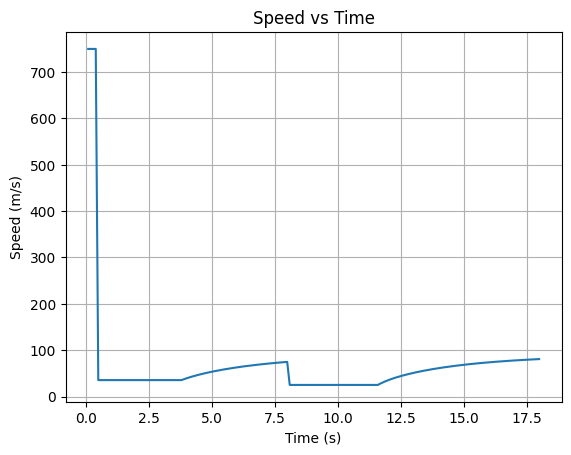

In [10]:
if __name__ == "__main__":
    # Define car
    car = Car(
        mass=800,        # kg
        power=600_000,   # watts
        cd=0.9,
        area=1.5,
        mu=1.6
    )

    # Define track
    track = [
        TrackSegment(300, np.inf),   # straight
        TrackSegment(120, 80),       # corner
        TrackSegment(250, np.inf),
        TrackSegment(90, 40),
        TrackSegment(400, np.inf)
    ]

    times, dist, speeds = simulate_lap(car, track)
    lap_time = times[-1]

    print(f"Lap Time: {lap_time:.2f} seconds")

    plt.plot(times, speeds)
    plt.xlabel("Time (s)")
    plt.ylabel("Speed (m/s)")
    plt.title("Speed vs Time")
    plt.grid(True)
    plt.show()

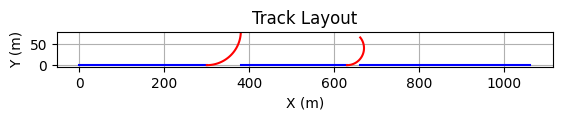

In [11]:
## display the track layout
fig, ax = plt.subplots()
current_x = 0
for segment in track: 
    if segment.radius == float('inf'):
        ax.plot([current_x, current_x + segment.length], [0, 0], 'b-')
        current_x += segment.length
    else:
        theta = segment.length / segment.radius
        arc = np.linspace(0, theta, 100)
        x_arc = current_x + segment.radius * np.sin(arc)
        y_arc = segment.radius * (1 - np.cos(arc))
        ax.plot(x_arc, y_arc, 'r-')
        current_x += segment.radius * np.sin(theta)
ax.set_aspect('equal', 'box')
ax.set_title("Track Layout")
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
plt.grid(True)
plt.show()